# Unit V Practical: Association Rule Mining and Anomaly Detection

**Aim:** To discover buying patterns with **Apriori** and **FP-Growth** (Market Basket Analysis), and to detect
unusual network connections with **Isolation Forest** and **Local Outlier Factor (LOF)**.

### Practicals covered
| Practical | Task | Dataset |
|---|---|---|
| 11 | Market Basket Analysis with Apriori and FP-Growth; interpret association rules | Grocery store transactions |
| 12 | Compare Isolation Forest and LOF for finding unusual observations | KDD Cup 99 network traffic (cybersecurity) |

### Syllabus covered
- Support, Confidence, Lift, Conviction
- Apriori and FP-Growth algorithms
- Anomaly vs. novelty detection
- Isolation Forest and Local Outlier Factor
- Applications in cybersecurity and fraud detection

> Run the cells from top to bottom. Each output is followed by a short note on **what to look for**.

## 0. Install mlxtend (Google Colab)

`mlxtend` provides Apriori, FP-Growth and association rules.

In [ ]:
!pip install -q mlxtend

In [2]:
# Step 1: Import libraries

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

from sklearn.datasets import fetch_kddcup99
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA

pd.set_option("display.width", 140)
print("Libraries imported successfully!")

Libraries imported successfully!


# Practical 11 – Market Basket Analysis

## 1. The four measures, on a small example first

Below are 10 bills from a small shop. Each bill is the set of items bought together.
We work out the measures **by hand in Python** before using any library.

| Measure | Formula | Meaning |
|---|---|---|
| **Support(A)** | bills containing A / all bills | How common A is |
| **Confidence(A → B)** | Support(A and B) / Support(A) | Of the bills with A, what fraction also has B |
| **Lift(A → B)** | Confidence(A → B) / Support(B) | > 1: A and B are bought together **more than by chance** |
| **Conviction(A → B)** | (1 − Support(B)) / (1 − Confidence(A → B)) | > 1: the rule is reliable; larger is stronger |

In [3]:
bills = [
    {"bread", "butter", "milk"},
    {"bread", "butter"},
    {"bread", "milk"},
    {"tea", "sugar", "biscuits"},
    {"bread", "butter", "jam"},
    {"tea", "sugar"},
    {"milk", "biscuits"},
    {"bread", "butter", "milk", "tea"},
    {"tea", "biscuits"},
    {"bread", "jam"},
]

def support(items):
    return sum(items <= bill for bill in bills) / len(bills)

A, B = {"bread"}, {"butter"}
s_a, s_b, s_ab = support(A), support(B), support(A | B)
confidence = s_ab / s_a
lift = confidence / s_b
conviction = (1 - s_b) / (1 - confidence)

print("Rule: bread -> butter")
print("Support(bread)          =", s_a)
print("Support(butter)         =", s_b)
print("Support(bread & butter) =", s_ab)
print("Confidence              =", round(confidence, 3))
print("Lift                    =", round(lift, 3))
print("Conviction              =", round(conviction, 3))

Rule: bread -> butter
Support(bread)          = 0.6
Support(butter)         = 0.4
Support(bread & butter) = 0.4
Confidence              = 0.667
Lift                    = 1.667
Conviction              = 1.8


**What to look for:** 4 of the 6 bread bills also contain butter (confidence ≈ 0.67).
Lift is above 1, so buying bread really does make butter more likely than usual.

## 2. Encode the bills as a table

Libraries need a **True/False table**: one row per bill and one column per item.
`TransactionEncoder` does this.

In [4]:
encoder = TransactionEncoder()
small_table = pd.DataFrame(encoder.fit(bills).transform(bills), columns=encoder.columns_)
small_table

,biscuits,bread,butter,jam,milk,sugar,tea
0,False,True,True,False,True,False,False
1,False,True,True,False,False,False,False
2,False,True,False,False,True,False,False
3,True,False,False,False,False,True,True
4,False,True,True,True,False,False,False
5,False,False,False,False,False,True,True
6,True,False,False,False,True,False,False
7,False,True,True,False,True,False,True
8,True,False,False,False,False,False,True
9,False,True,False,True,False,False,False


In [5]:
small_itemsets = apriori(small_table, min_support=0.3, use_colnames=True)

def make_rules(itemsets, n_bills, min_confidence):
    # This works with both old and new versions of mlxtend
    try:
        return association_rules(itemsets, num_itemsets=n_bills, metric="confidence",
                                 min_threshold=min_confidence)
    except TypeError:
        return association_rules(itemsets, metric="confidence", min_threshold=min_confidence)

small_rules = make_rules(small_itemsets, len(bills), 0.6)
small_rules[["antecedents", "consequents", "support", "confidence", "lift", "conviction"]].round(3)

,antecedents,consequents,support,confidence,lift,conviction
0,frozenset({bread}),frozenset({butter}),0.4,0.667,1.667,1.8
1,frozenset({butter}),frozenset({bread}),0.4,1.000,1.667,inf
2,frozenset({milk}),frozenset({bread}),0.3,0.750,1.250,1.6


**What to look for:** the library gives the **same numbers** for bread → butter as our hand calculation.
Now we can trust it on a bigger dataset.

## 3. A full store dataset

We now use **2,000 bills** from a grocery store with 16 products. (The bills are generated with a fixed random
seed so everyone gets the same data. Some products are bought together more often, as in a real store.)

In [6]:
rng = np.random.default_rng(7)
products = ["bread", "butter", "milk", "eggs", "jam", "tea", "sugar", "biscuits",
            "coffee", "rice", "dal", "cooking oil", "chips", "cold drink", "curd", "paneer"]
popularity = np.array([.30, .10, .35, .20, .06, .25, .12, .15, .10, .22, .10, .12, .15, .08, .18, .08])

store_bills = []
for _ in range(2000):
    bill = {p for p, chance in zip(products, popularity) if rng.random() < chance}
    if "bread" in bill and rng.random() < 0.55: bill.add("butter")
    if "tea" in bill and rng.random() < 0.60: bill.add("sugar")
    if "tea" in bill and rng.random() < 0.40: bill.add("biscuits")
    if "rice" in bill and rng.random() < 0.55: bill.add("dal")
    if "chips" in bill and rng.random() < 0.60: bill.add("cold drink")
    if "paneer" in bill and rng.random() < 0.50: bill.add("curd")
    if not bill:
        bill.add("milk")
    store_bills.append(sorted(bill))

encoder = TransactionEncoder()
store = pd.DataFrame(encoder.fit(store_bills).transform(store_bills), columns=encoder.columns_)

print("Bills:", store.shape[0], "  Products:", store.shape[1])
print("Average items per bill:", round(store.sum(axis=1).mean(), 2))
store.mean().sort_values(ascending=False).round(3).rename("support").to_frame().T

Bills: 2000   Products: 16
Average items per bill: 3.2


,milk,bread,tea,sugar,butter,biscuits,rice,curd,eggs,dal,chips,cold drink,cooking oil,coffee,paneer,jam
support,0.408,0.298,0.262,0.25,0.25,0.236,0.218,0.215,0.201,0.2,0.148,0.145,0.117,0.106,0.078,0.066


**What to look for:** the last line is the **support of every single product**. Milk and bread are the
most common; jam and paneer are the rarest.

## 4. Apriori – find frequent itemsets

Apriori builds itemsets **level by level** (1 item, then 2, then 3 ...). It uses one rule to save work:
*if an itemset is rare, every bigger itemset that contains it is also rare*, so it never checks those.

In [7]:
start = time.time()
itemsets_apriori = apriori(store, min_support=0.03, use_colnames=True)
time_apriori = time.time() - start

itemsets_apriori["size"] = itemsets_apriori["itemsets"].apply(len)
print("Frequent itemsets found:", len(itemsets_apriori))
print(itemsets_apriori["size"].value_counts().sort_index().rename("count of itemsets by size"))
itemsets_apriori.sort_values("support", ascending=False).head(10)

Frequent itemsets found: 110
size
1    16
2    70
3    24
Name: count of itemsets by size, dtype: int64


,support,itemsets,size
11,0.4085,frozenset({milk}),1
1,0.2975,frozenset({bread}),1
15,0.2620,frozenset({tea}),1
14,0.2500,frozenset({sugar}),1
2,0.2495,frozenset({butter}),1
0,0.2365,frozenset({biscuits}),1
13,0.2185,frozenset({rice}),1
7,0.2150,frozenset({curd}),1
9,0.2010,frozenset({eggs}),1
8,0.2005,frozenset({dal}),1


## 5. FP-Growth – the same result, a different method

FP-Growth first squeezes all bills into a compact tree (the **FP-tree**) and then reads frequent itemsets from it,
without generating candidate itemsets level by level. It must find **exactly the same** itemsets as Apriori.

In [8]:
start = time.time()
itemsets_fp = fpgrowth(store, min_support=0.03, use_colnames=True)
time_fp = time.time() - start

same = set(map(frozenset, itemsets_apriori["itemsets"])) == set(map(frozenset, itemsets_fp["itemsets"]))
print("Itemsets found by FP-Growth:", len(itemsets_fp))
print("Same itemsets as Apriori?   ", same)
print(f"Apriori time:   {time_apriori:.3f} s")
print(f"FP-Growth time: {time_fp:.3f} s")

Itemsets found by FP-Growth: 110
Same itemsets as Apriori?    True
Apriori time:   0.005 s
FP-Growth time: 0.015 s


**What to look for:** both methods find the **same itemsets**; only the way of searching differs.
On large stores with many products, FP-Growth is usually faster because it does not generate candidates.
(On this small dataset both are fast, so the times may be close.)

## 6. Generate and filter association rules

In [9]:
rules = make_rules(itemsets_fp, len(store), 0.4)
rules["rule"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s))) + "  ->  " + \
                rules["consequents"].apply(lambda s: ", ".join(sorted(s)))

strong = rules[rules["lift"] > 1.2].sort_values("lift", ascending=False)
strong[["rule", "support", "confidence", "lift", "conviction"]].round(3).head(12)

,rule,support,confidence,lift,conviction
26,"cold drink, milk -> chips",0.034,0.660,4.446,2.506
25,"chips, milk -> cold drink",0.034,0.624,4.302,2.273
23,chips -> cold drink,0.086,0.576,3.971,2.015
24,cold drink -> chips,0.086,0.590,3.971,2.075
9,"biscuits, sugar -> tea",0.078,0.834,3.184,4.452
57,paneer -> curd,0.049,0.632,2.941,2.135
31,rice -> dal,0.126,0.579,2.888,1.899
32,dal -> rice,0.126,0.631,2.888,2.117
38,"bread, dal -> rice",0.036,0.628,2.876,2.103
41,"rice, tea -> dal",0.032,0.571,2.850,1.866


**What to look for:** these are rules with confidence ≥ 0.4 **and** lift > 1.2.
The top rules are the product pairs that customers buy together far more often than chance.

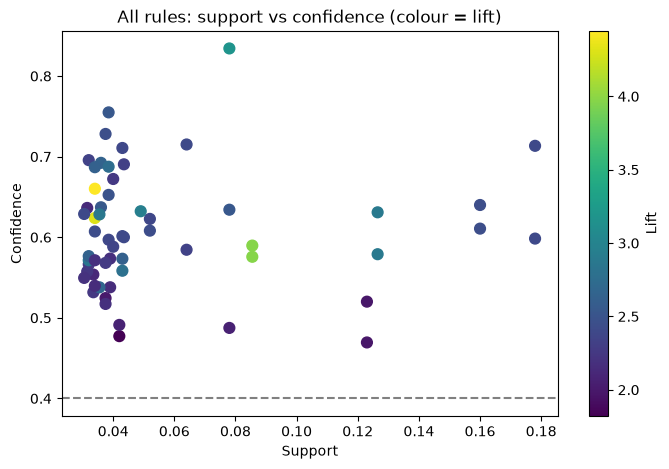

In [10]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=60)
plt.colorbar(sc, label="Lift")
plt.axhline(0.4, linestyle="--", color="grey")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("All rules: support vs confidence (colour = lift)")
plt.show()

**What to look for:** a rule can have high confidence but lift near 1 (the right-hand item is simply popular,
like milk). The bright, high-lift points are the **useful** patterns.

## 7. Turn rules into business actions

In [11]:
for _, r in strong.head(5).iterrows():
    a = ", ".join(sorted(r["antecedents"]))
    b = ", ".join(sorted(r["consequents"]))
    print(f"* {r['confidence'] * 100:.0f}% of bills with [{a}] also have [{b}] "
          f"- {r['lift']:.1f} times more often than usual.")
    print(f"  Action: place {b} near {a}, or offer a combo deal.\n")

* 66% of bills with [cold drink, milk] also have [chips] - 4.4 times more often than usual.
  Action: place chips near cold drink, milk, or offer a combo deal.

* 62% of bills with [chips, milk] also have [cold drink] - 4.3 times more often than usual.
  Action: place cold drink near chips, milk, or offer a combo deal.

* 58% of bills with [chips] also have [cold drink] - 4.0 times more often than usual.
  Action: place cold drink near chips, or offer a combo deal.

* 59% of bills with [cold drink] also have [chips] - 4.0 times more often than usual.
  Action: place chips near cold drink, or offer a combo deal.

* 83% of bills with [biscuits, sugar] also have [tea] - 3.2 times more often than usual.
  Action: place tea near biscuits, sugar, or offer a combo deal.



### Practical 11 – Result
Apriori and FP-Growth found the same frequent itemsets. Rules with **high lift** revealed real buying patterns
(for example tea with sugar, chips with cold drinks), which a store can use for shelf placement and offers.
Confidence alone can mislead when the second item is very popular, so always check **lift**.

# Practical 12 – Anomaly Detection: Isolation Forest vs LOF

## 8. Anomaly or novelty?

| | Anomaly (outlier) detection | Novelty detection |
|---|---|---|
| Training data | May already **contain** some unusual points | **Clean**, only normal points |
| Question | Which points in **this data** are unusual? | Is a **new** point different from what we have seen? |
| Example | Find suspicious connections in today's network log | Check each new login against normal behaviour |

## 9. The two methods in one minute

**Isolation Forest:** keep cutting the data at random places. An unusual point sits far from the others, so it
gets **separated (isolated) after only a few cuts**. Fewer cuts → higher anomaly score.

**Local Outlier Factor (LOF):** compare how crowded each point's neighbourhood is with how crowded its
**neighbours'** neighbourhoods are. A point in a much **emptier area than its neighbours** is an outlier.
A score near 1 is normal; clearly above 1 is unusual.

## 10. Load the network-traffic data

**KDD Cup 99** is a real cybersecurity dataset of network connections. Most connections are normal; a few are
**attacks**. We use the `SA` version (mostly normal traffic with a small share of attacks) and take a sample
of 6,000 connections. The attack labels are **not** given to the models; we use them only to check the results.

In [12]:
kdd = fetch_kddcup99(subset="SA", percent10=True, as_frame=True, random_state=42)
traffic = kdd.frame.sample(6000, random_state=42).reset_index(drop=True)

# Labels are stored as bytes, e.g. b'normal.' or b'smurf.'; decode them to text
traffic["label"] = traffic["labels"].apply(lambda v: v.decode() if isinstance(v, bytes) else str(v))
traffic["is_attack"] = (traffic["label"] != "normal.").astype(int)

print("Connections:", len(traffic))
print("Attacks    :", traffic["is_attack"].sum(), f"({traffic['is_attack'].mean() * 100:.1f} %)")

Connections: 6000
Attacks    : 197 (3.3 %)


## 11. Choose features and prepare them

We use 10 numeric features that describe each connection: how long it lasted, how many bytes were sent and
received, and how many recent connections went to the same host or service.

Byte counts range from 0 to millions, so we apply `log1p` (log of 1 + value) to shrink huge values, then standardize.

In [13]:
features = ["duration", "src_bytes", "dst_bytes", "count", "srv_count", "serror_rate",
            "same_srv_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate"]

X_net = traffic[features].astype(float)
for col in ["duration", "src_bytes", "dst_bytes"]:
    X_net[col] = np.log1p(X_net[col])

X_net_scaled = StandardScaler().fit_transform(X_net)
y_attack = traffic["is_attack"].values

X_net.describe().loc[["mean", "min", "max"]].round(2)

,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate
mean,0.43,5.18,5.58,21.26,21.96,0.01,0.98,152.09,204.03,0.85
min,0.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,1.00,0.00
max,9.90,14.60,12.52,511.00,511.00,1.00,1.00,255.00,255.00,1.00


## 12. Run Isolation Forest and LOF

Both models give each connection an **anomaly score** (higher = more unusual). We tell each model to flag the
top 3 % as anomalies (`contamination=0.03`), a little below the real attack rate.

In [14]:
start = time.time()
iso = IsolationForest(n_estimators=200, contamination=0.03, random_state=42).fit(X_net_scaled)
iso_score = -iso.score_samples(X_net_scaled)
iso_flag = (iso.predict(X_net_scaled) == -1).astype(int)
time_iso = time.time() - start

start = time.time()
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
lof_flag = (lof.fit_predict(X_net_scaled) == -1).astype(int)
lof_score = -lof.negative_outlier_factor_
time_lof = time.time() - start

print("Connections flagged by Isolation Forest:", iso_flag.sum())
print("Connections flagged by LOF             :", lof_flag.sum())

Connections flagged by Isolation Forest: 142
Connections flagged by LOF             : 180


**Note:** LOF may print a warning about **duplicate values**. This is not an error. Many connections in this data are
**exact copies** of each other (an attack often sends the same connection hundreds of times). LOF compares each point with
its 20 nearest neighbours, and when those neighbours are identical copies, the point does not look unusual at all.
Keep this in mind for Section 13.

## 13. Check against the real attack labels

In [15]:
def report(name, flag, score, seconds):
    caught = int(((flag == 1) & (y_attack == 1)).sum())
    return {
        "Method": name,
        "Flagged": int(flag.sum()),
        "Flagged that are real attacks": caught,
        "Precision (flagged that are attacks)": round(caught / flag.sum(), 3),
        "Recall (attacks found)": round(caught / y_attack.sum(), 3),
        "ROC-AUC of score": round(roc_auc_score(y_attack, score), 3),
        "Time (s)": round(seconds, 2),
    }

comparison = pd.DataFrame([
    report("Isolation Forest", iso_flag, iso_score, time_iso),
    report("LOF", lof_flag, lof_score, time_lof),
])
comparison.T

,0,1
Method,Isolation Forest,LOF
Flagged,142,180
Flagged that are real attacks,102,36
Precision (flagged that are attacks),0.718,0.2
Recall (attacks found),0.518,0.183
ROC-AUC of score,0.994,0.478
Time (s),0.52,0.38


**How to read this table:**
- **Precision:** of the connections a method flagged, how many were really attacks.
- **Recall:** of all real attacks, how many the method found.
- **ROC-AUC:** how well the score ranks attacks above normal traffic over all thresholds (1 = perfect, 0.5 = random).

On this data, **Isolation Forest** separates attacks much better. Many attacks here are fast bursts of very
similar connections. They are unusual compared with all traffic (easy to isolate), but they sit in **dense groups**
of their own, so LOF sees them as having crowded neighbourhoods and does not call them outliers.
This is the key difference: **Isolation Forest looks for globally unusual points; LOF looks for locally isolated points.**

## 14. See the flagged points

We use PCA (Unit IV) only to draw the 10-feature data in 2D.

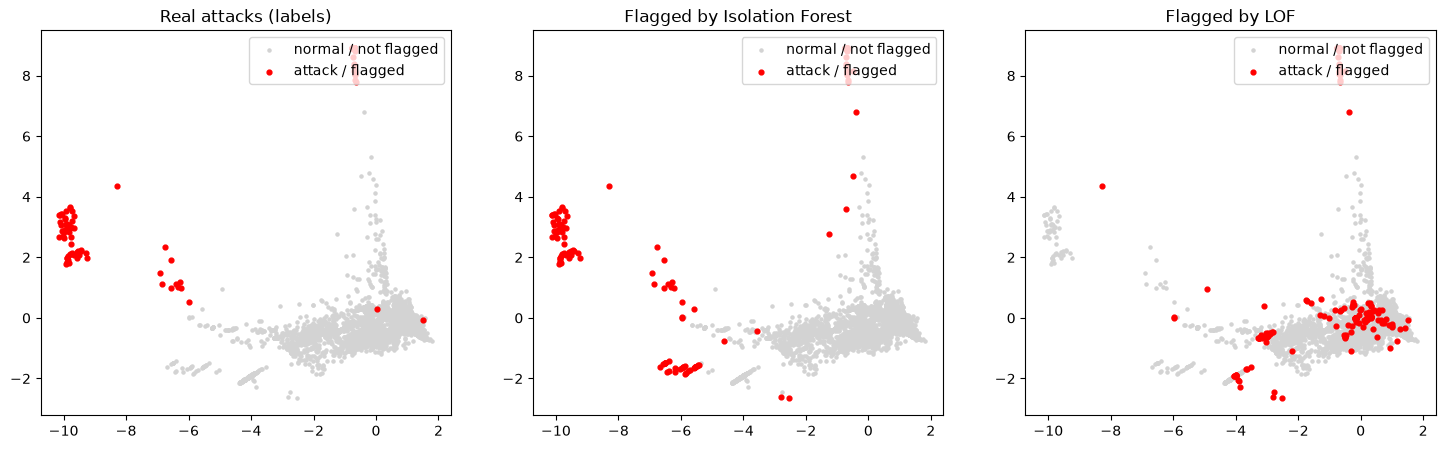

In [16]:
view = PCA(n_components=2, random_state=42).fit_transform(X_net_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
panels = [("Real attacks (labels)", y_attack), ("Flagged by Isolation Forest", iso_flag), ("Flagged by LOF", lof_flag)]
for ax, (title, mark) in zip(axes, panels):
    ax.scatter(view[mark == 0, 0], view[mark == 0, 1], s=5, c="lightgrey", label="normal / not flagged")
    ax.scatter(view[mark == 1, 0], view[mark == 1, 1], s=12, c="red", label="attack / flagged")
    ax.set_title(title)
    ax.legend(loc="upper right")
plt.show()

**What to look for:** compare the red points in the middle and right panels with the left panel.
The method whose red points match the left panel more closely is the better detector for this kind of attack.

## 15. Novelty detection: train on normal traffic only

For **novelty detection**, LOF is trained only on **normal** connections (`novelty=True`), and then asked about
**new** connections it has never seen.

In [17]:
normal_part = X_net_scaled[y_attack == 0]
train_normal = normal_part[:3000]                    # clean training data: normal only
new_data = np.vstack([normal_part[3000:4000],         # 1000 new normal connections
                      X_net_scaled[y_attack == 1]])  # plus all attack connections
new_truth = np.r_[np.zeros(1000), np.ones((y_attack == 1).sum())]

novelty_lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(train_normal)
new_flag = (novelty_lof.predict(new_data) == -1).astype(int)

print("New normal connections flagged as novel:", int(new_flag[new_truth == 0].sum()), "of 1000")
print("New attack connections flagged as novel:", int(new_flag[new_truth == 1].sum()), "of", int(new_truth.sum()))

New normal connections flagged as novel: 104 of 1000
New attack connections flagged as novel: 194 of 197


**What to look for:** when LOF learns only from **clean normal traffic**, it flags most attacks as **new and
different**, while most new normal connections pass. The same method works much better here because the attack
groups are no longer part of the data it learned from.

## 16. Quick Comparison

| | Isolation Forest | Local Outlier Factor (LOF) |
|---|---|---|
| Idea | Unusual points are isolated with few random cuts | Point is in a much emptier area than its neighbours |
| Looks at | The whole dataset (global) | The local neighbourhood |
| Good at | Points far from everything else | Points that are odd **for their area** |
| Weak at | Small local outliers next to a dense cluster | Unusual points that form their own dense group |
| Speed on large data | Fast | Slower (needs neighbours of every point) |
| Novelty detection | Yes | Yes, with `novelty=True` |

## Conclusion

Apriori and FP-Growth discovered the same frequent itemsets in 2,000 grocery bills, and **lift** separated real
buying patterns from items that are simply popular. On real network traffic, Isolation Forest ranked the attacks
almost perfectly (ROC-AUC close to 1), and about half of all attacks were among the 3 % of connections it flagged, while
LOF did no better than chance, because the attacks formed dense groups of their own. Training LOF on clean normal traffic
(**novelty detection**) made it effective. The right anomaly method depends on **what the unusual points look
like**, and on whether we have **clean normal data** to learn from.